# 원하는 포즈로 이미지 만드는 도구 (FLUX.2-klein 4B + OpenPose)

참조 사진 한 장에서 **OpenPose로 관절(뼈대)을 뽑고**, 그 뼈대를 **FLUX.2-klein 4B에 참조 이미지로 넣어** 프롬프트가 묘사하는 다른 인물·장면을 **같은 자세로** 그립니다.

출발점은 교안의 [FLUX.2-klein 4B Colab 노트](https://colab.research.google.com/drive/1axPf8sqixd2uksu-6_ZMFdpuU_fWfEPS?usp=sharing)입니다. 단계 1~4(GPU 확인, ComfyUI 설치, 모델 다운로드, 서버 실행)는 그 노트와 같고, 단계 5부터가 포즈 조건을 얹은 부분입니다.

```
참조 사진 ──OpenPose──▶ 뼈대 그림 ──VAE 인코딩──▶ ReferenceLatent ─┐
프롬프트 ──텍스트 인코더(Qwen3-4B)──────────────────────────────────┴▶ FLUX.2-klein 4B ──▶ 같은 자세의 새 그림
```

### 왜 ControlNet이 아니라 "참조 이미지(ReferenceLatent)"인가
- FLUX.2에는 아직 **공식 ControlNet이 없습니다**(교안 4절). 안정적인 포즈 ControlNet은 FLUX.1-dev 쪽인데, 12B라 무료 T4에서는 무겁습니다.
- 대신 FLUX.2는 한 모델로 **여러 장의 참조 이미지(multi-reference)** 를 받아 편집할 수 있습니다. 그래서 OpenPose 뼈대 그림을 참조 이미지로 넣고, 프롬프트로 "이 뼈대의 자세 그대로 그려라"라고 지시합니다.
- 비유: ControlNet은 **밑그림 위에 트레이싱지를 대고 그리는 것**, 이 방식은 **옆에 포즈 참고 그림을 붙여 두고 보면서 그리는 것**에 가깝습니다. 트레이싱처럼 선을 강제로 따르지는 않으므로, 자세가 얼마나 따라오는지는 단계 8에서 다시 뼈대를 뽑아 확인합니다.

### 실행 순서
1. 상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 를 고르고 저장합니다.
2. 셀을 **위에서부터 순서대로** 실행합니다. 모델 다운로드(약 11GB)에 시간이 걸립니다.
3. 결과는 `/content/pose-image-tool/samples/` 에 쌓이고, 마지막 코드 셀에서 zip으로 내려받습니다.

| 단계 | 하는 일 |
|---|---|
| 1 | GPU 확인 |
| 2 | ComfyUI + GGUF 노드 + OpenPose 도구 설치 |
| 3 | 모델 파일 3종 다운로드 |
| 4 | ComfyUI 서버 실행 |
| 5 | 참조 사진 준비 + 포즈(뼈대) 추출 |
| 6 | 포즈 조건 생성 함수 정의 |
| 7 | 한 장 만들고 samples/ 에 저장 |
| 8 | 결과에서 다시 뼈대를 뽑아 자세 비교 |
| 9 | 조건 실험 A·B (포즈 고정·프롬프트 변경 / 프롬프트 고정·포즈 변경) |
| 10 | prompts.md 작성 + 결과 내려받기 |
| 끝 | 관찰 기록 (마지막 마크다운 셀) |

## [단계 1] 런타임에 GPU가 있는지 확인

이 실습은 GPU 없이는 실행할 수 없습니다. 현재 런타임이 GPU를 인식하는지, 종류(T4 등)와 VRAM이 얼마인지 확인합니다. GPU가 없으면 **[런타임 → 런타임 유형 변경 → T4 GPU]** 후 다시 실행합니다.

In [1]:
# [단계 1] 이 셀이 하는 일: GPU가 잡혀 있는지, 이름과 VRAM 크기를 출력한다.
import torch

print("PyTorch 버전:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    raise RuntimeError("GPU가 없습니다. [런타임 → 런타임 유형 변경 → T4 GPU] 후 다시 실행하세요.")

PyTorch 버전: 2.14.1+cu130
CUDA 사용 가능: True
GPU: Tesla T4
VRAM(GB): 15.64


## [단계 2] ComfyUI, GGUF 노드, OpenPose 도구 설치

- **ComfyUI**: 모델 로드·텍스트 인코딩·샘플링을 노드로 이어 붙이는 이미지 생성 도구입니다. 여기서는 화면 없이 **API 서버**로만 씁니다.
- **ComfyUI-GGUF**: 4비트로 줄인(GGUF) 모델을 읽는 플러그인입니다.
- **controlnet_aux**: 사진에서 사람의 관절을 찾아 뼈대 그림으로 그려 주는 **OpenPose** 검출기가 들어 있습니다. (원본 노트에 새로 더한 부분)

In [2]:
# [단계 2] 이 셀이 하는 일: ComfyUI 본체, GGUF 로더 노드, OpenPose 검출기(controlnet_aux)를 설치한다.
import os

%cd /content
if not os.path.isdir("/content/ComfyUI"):
    !git clone https://github.com/comfyanonymous/ComfyUI.git        # ComfyUI 본체

%cd /content/ComfyUI
!pip install -q -r requirements.txt                                     # ComfyUI 의존성

%cd /content/ComfyUI/custom_nodes
if not os.path.isdir("ComfyUI-GGUF"):
    !git clone https://github.com/city96/ComfyUI-GGUF.git                # GGUF 로더 노드
%cd /content/ComfyUI
!pip install -q gguf                                                    # GGUF 파싱 라이브러리
!pip install -q controlnet_aux                                          # OpenPose 검출기 (새로 추가)

print("\n완료: ComfyUI + GGUF 노드 + controlnet_aux 설치")

/content
Cloning into 'ComfyUI'...
remote: Enumerating objects: 65059, done.
remote: Counting objects: 100% (837/837), done.
remote: Compressing objects: 100% (258/258), done.
remote: Total 65059 (delta 708), reused 588 (delta 579), pack-reused 64222 (from 4)
Receiving objects: 100% (65059/65059), 99.96 MiB | 17.24 MiB/s, done.
Resolving deltas: 100% (45018/45018), done.
/content/ComfyUI
/content/ComfyUI/custom_nodes
Cloning into 'ComfyUI-GGUF'...
remote: Enumerating objects: 814, done.
remote: Counting objects: 100% (570/570), done.
remote: Compressing objects: 100% (207/207), done.
remote: Total 814 (delta 515), reused 363 (delta 363), pack-reused 244 (from 1)
Receiving objects: 100% (814/814), 187.88 KiB | 3.48 MiB/s, done.
Resolving deltas: 100% (545/545), done.
/content/ComfyUI

완료: ComfyUI + GGUF 노드 + controlnet_aux 설치


## [단계 3] 모델 파일 3종 다운로드

| 역할 | 파일 | 크기 |
|---|---|---|
| 디퓨전 모델 | `flux-2-klein-4b-Q4_K_M.gguf` | 약 2.6GB |
| 텍스트 인코더 | `qwen_3_4b.safetensors` | 약 8GB |
| VAE | `flux2-vae.safetensors` | 약 330MB |

이미 받은 파일은 건너뛰므로, 런타임이 끊긴 뒤 다시 실행해도 처음부터 받지 않습니다. FLUX.2-klein **4B는 아파치 2.0** 라이선스라 결과물을 공개 저장소에 올려도 됩니다(9B는 비상업).

In [3]:
# [단계 3] 이 셀이 하는 일: 모델 3종을 ComfyUI 표준 폴더에 내려받는다(이미 있으면 건너뜀).
import os
%cd /content/ComfyUI

os.makedirs("models/diffusion_models", exist_ok=True)
os.makedirs("models/text_encoders", exist_ok=True)
os.makedirs("models/vae", exist_ok=True)

def 다운로드(url, 저장경로):
    # 이미 받았으면 건너뛰고, 아니면 wget으로 받는다
    if os.path.exists(저장경로) and os.path.getsize(저장경로) > 1_000_000:
        print(f"  ↳ 이미 있음: {저장경로} ({os.path.getsize(저장경로)/1e9:.2f} GB)")
        return
    print("  ↳ 다운로드 중...")
    !wget -q --show-progress -O "{저장경로}" "{url}"

print("[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)")
다운로드("https://huggingface.co/unsloth/FLUX.2-klein-4B-GGUF/resolve/main/flux-2-klein-4b-Q4_K_M.gguf",
        "models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf")
print("[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors",
        "models/text_encoders/qwen_3_4b.safetensors")
print("[3/3] VAE (약 330MB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/vae/flux2-vae.safetensors",
        "models/vae/flux2-vae.safetensors")

!ls -lh models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf models/text_encoders/qwen_3_4b.safetensors models/vae/flux2-vae.safetensors

/content/ComfyUI
[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)
  ↳ 다운로드 중...
models/diffusion_mo 100%[===================>]   2.42G  98.4MB/s    in 28s     
[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)
  ↳ 다운로드 중...
models/text_encoder 100%[===================>]   7.49G   140MB/s    in 78s     
[3/3] VAE (약 330MB)
  ↳ 다운로드 중...
models/vae/flux2-va 100%[===================>] 320.64M   128MB/s    in 2.5s    
-rw-r--r-- 1 root root 2.5G Nov 11 06:37 models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf
-rw-r--r-- 1 root root 7.5G Nov 11 06:38 models/text_encoders/qwen_3_4b.safetensors
-rw-r--r-- 1 root root 321M Nov 11 06:38 models/vae/flux2-vae.safetensors


## [단계 4] ComfyUI 서버 실행

ComfyUI를 백그라운드로 띄웁니다. 서버는 Colab 안의 `http://127.0.0.1:8188` 에서 HTTP API로 동작하고, 단계 6의 생성 함수가 여기에 워크플로를 보냅니다. `http 200` 응답이 오면 준비된 것입니다.

In [4]:
# [단계 4] 이 셀이 하는 일: ComfyUI 서버를 백그라운드로 실행하고, 응답이 올 때까지 기다린다.
import subprocess, os, time
%cd /content/ComfyUI

!pkill -f "main.py" 2>/dev/null
time.sleep(2)
os.system("nohup python main.py --listen 0.0.0.0 --port 8188 > /content/comfyui.log 2>&1 &")

print("ComfyUI 기동 대기 중...")
for _ in range(60):
    time.sleep(1)
    code = subprocess.run("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/",
                          shell=True, capture_output=True, text=True).stdout
    if code == "200":
        print("완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)")
        break
else:
    print("서버가 안 뜹니다. 로그 끝부분:")
    print(open("/content/comfyui.log").read()[-800:])

/content/ComfyUI
^C
ComfyUI 기동 대기 중...
완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)


## [단계 5] 참조 사진 준비 + 포즈(뼈대) 추출

1. 참조 사진 두 장을 `/content/ref/` 에 둡니다. 기본값은 공개 예제 사진 두 장(서 있는 자세, 팔을 모은 상반신)입니다.
   - **내 사진을 쓰려면** 아래 `UPLOAD = True` 로 바꾸고 실행하면 파일 선택 창이 뜹니다. 올린 순서대로 `pose_01`, `pose_02` … 가 됩니다.
   - 공개 저장소에 올리므로 **얼굴이 드러난 실존 인물 사진·출처가 불분명한 사진은 피하고**, 직접 찍은 사진이나 자유 이용 사진을 권합니다.
2. 사진 크기를 **긴 변 1024px, 64의 배수**로 맞춥니다(모델이 받는 크기 단위).
3. **OpenPose**가 관절 위치를 찾아 색 막대로 이은 **뼈대 그림**을 만듭니다. 몸통·팔다리에 손·얼굴 점까지 넣습니다.

> 비유: OpenPose는 사진 위에 **관절 스티커를 붙이고 선으로 잇는 일**입니다. 다만 가려진 관절(등 뒤로 간 손 등)은 스티커를 붙일 수 없어 빠지고, 그 부분은 모델이 짐작으로 채웁니다.

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarni

body_pose_model.pth: reconstructing file:   0%|          |  0.00B /  209MB            

body_pose_model.pth: downloading bytes:           |  0.00B            

hand_pose_model.pth: reconstructing file:   0%|          |  0.00B /  147MB            

hand_pose_model.pth: downloading bytes:           |  0.00B            

facenet.pth: reconstructing file:   0%|          |  0.00B /  154MB            

facenet.pth: downloading bytes:           |  0.00B            

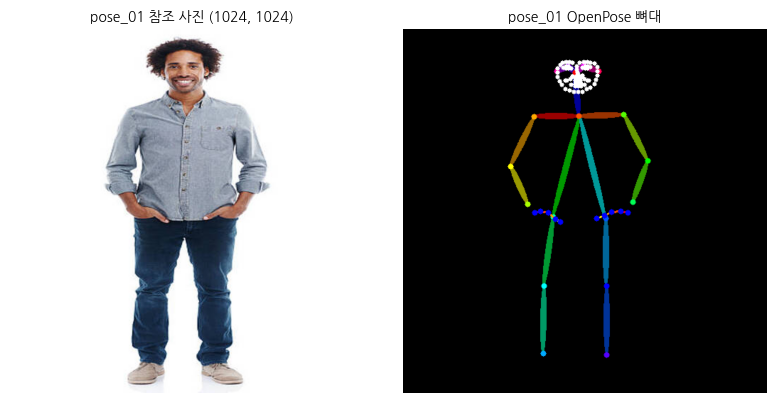

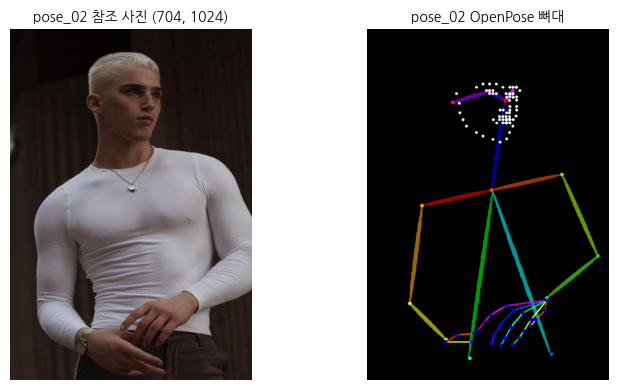

In [5]:
# [단계 5] 이 셀이 하는 일: 참조 사진을 받아 크기를 맞추고, OpenPose로 뼈대 그림을 만들어 보여 준다.
import os, requests, io
from PIL import Image
import matplotlib.pyplot as plt
from controlnet_aux import OpenposeDetector

UPLOAD = False          # True로 바꾸면 내 사진을 올릴 수 있다
MAX_SIDE = 1024         # 긴 변 크기. 느리면 768로 낮춘다

REF_DIR = "/content/ref"
OUT_DIR = "/content/pose-image-tool/samples"
os.makedirs(REF_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# 기본 참조 사진 (공개 예제 이미지)
DEFAULT_REFS = {
    "pose_01": "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/person.png",
    "pose_02": "https://huggingface.co/lllyasviel/sd-controlnet-openpose/resolve/main/images/pose.png",
}

def fit_size(img):
    # 비율을 지키며 긴 변을 MAX_SIDE로, 가로·세로를 64의 배수로 맞춘다
    w, h = img.size
    s = MAX_SIDE / max(w, h)
    return img.resize((max(64, round(w * s / 64) * 64), max(64, round(h * s / 64) * 64)), Image.LANCZOS)

refs = {}
if UPLOAD:
    from google.colab import files
    for i, (name, data) in enumerate(files.upload().items(), 1):
        refs[f"pose_{i:02d}"] = fit_size(Image.open(io.BytesIO(data)).convert("RGB"))
else:
    for key, url in DEFAULT_REFS.items():
        refs[key] = fit_size(Image.open(io.BytesIO(requests.get(url, timeout=60).content)).convert("RGB"))

# OpenPose 검출기 로드 (처음 한 번 가중치를 내려받는다)
openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")

def extract_pose(img):
    # 사진 → 뼈대 그림. 결과를 원본과 같은 크기로 맞춰 돌려준다
    pose = openpose(img, include_hand=True, include_face=True)
    return pose.resize(img.size, Image.NEAREST)

skeletons = {}
for key, img in refs.items():
    img.save(f"{OUT_DIR}/{key}.png")                     # 참조 사진 → samples/pose_XX.png
    skeletons[key] = extract_pose(img)
    skeletons[key].save(f"{OUT_DIR}/{key}_skeleton.png")  # 뼈대 → samples/pose_XX_skeleton.png

!apt-get -qq install -y fonts-nanum > /dev/null                 # 그림 제목의 한글이 네모로 깨지지 않게
import matplotlib.font_manager as fm
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"

def show(images, titles, size=4):
    # 여러 장을 한 줄로 나란히 보여 주는 도우미
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, im, t in zip(axes if len(images) > 1 else [axes], images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()

for key in refs:
    show([refs[key], skeletons[key]], [f"{key} 참조 사진 {refs[key].size}", f"{key} OpenPose 뼈대"])

## [단계 6] 포즈 조건 생성 함수 정의

원본 노트의 `generate()` 워크플로에 노드 세 개를 더했습니다.

| 노드 | 하는 일 | 원본 노트와 차이 |
|---|---|---|
| `LoadImage` | ComfyUI `input/` 폴더의 뼈대 그림을 읽는다 | 추가 |
| `VAEEncode` | 뼈대 그림을 잠재 공간(latent)으로 압축한다 | 추가 |
| `ReferenceLatent` | 프롬프트 조건에 "이 그림을 참조하라"를 붙인다 | 추가 |
| `EmptyLatentImage` | 빈 캔버스. **참조 사진과 같은 크기**로 만든다 | 크기를 사진에 맞춤 |
| `KSampler` | 잡음을 걷어 내며 그림을 만든다 | `cfg` 4.0 → **1.0** |

- **`cfg`를 1.0으로 바꾼 이유**: 이 GGUF는 증류(distilled) 모델이라 4스텝·가이던스 1.0이 권장값입니다(교안 2절). 1.0이면 네거티브 프롬프트는 쓰이지 않습니다. 원본 값과 비교해 보고 싶으면 `generate(..., cfg=4.0)` 으로 바꿔 봅니다.
- **프롬프트 앞머리(`POSE_INSTRUCTION`)**: 모델이 뼈대 선 자체를 그려 버리지 않도록 "참조 그림은 자세 안내로만 쓰고, 사람만 그려라"를 문장으로(긍정형) 붙입니다. 뒤에는 교안의 여섯 칸(피사체·동작·카메라·조명·환경·스타일) 프롬프트가 옵니다.
- `ref="photo"` 로 부르면 뼈대 대신 **원본 사진**을 참조로 넣습니다. 뼈대 방식이 잘 안 따라올 때 비교용입니다.

In [6]:
# [단계 6] 이 셀이 하는 일: 뼈대 그림 + 프롬프트를 ComfyUI 워크플로로 조립해 보내고, 결과 이미지를 받아 온다.
import requests, time, json, urllib.parse, shutil

SERVER = "http://127.0.0.1:8188"
COMFY_INPUT = "/content/ComfyUI/input"
os.makedirs(COMFY_INPUT, exist_ok=True)

POSE_INSTRUCTION = (
    "The reference image is a colored OpenPose stick-figure skeleton used only as a pose guide. "
    "Generate a new photograph in which the person matches that skeleton exactly: "
    "same head direction, same shoulder line, same arm and hand positions, same leg and foot positions, same framing. "
    "The final image shows only the real person and the scene; the skeleton lines stay invisible. "
)

def generate(pose_key, prompt, seed=42, steps=4, cfg=1.0, ref="skeleton"):
    # pose_key: "pose_01" 등, ref: "skeleton"(뼈대) 또는 "photo"(원본 사진)
    ref_img = skeletons[pose_key] if ref == "skeleton" else refs[pose_key]
    ref_name = f"{pose_key}_{ref}.png"
    ref_img.save(f"{COMFY_INPUT}/{ref_name}")              # ComfyUI가 읽을 수 있게 input/에 둔다
    w, h = ref_img.size
    text = (POSE_INSTRUCTION if ref == "skeleton" else
            "Keep the exact body pose of the person in the reference image, but replace the person and scene as described. ") + prompt

    workflow = {
        "10": {"class_type": "UnetLoaderGGUF", "inputs": {"unet_name": "flux-2-klein-4b-Q4_K_M.gguf"}},       # 디퓨전 모델
        "8":  {"class_type": "CLIPLoader", "inputs": {"clip_name": "qwen_3_4b.safetensors", "type": "flux2"}},  # 텍스트 인코더
        "4":  {"class_type": "VAELoader", "inputs": {"vae_name": "flux2-vae.safetensors"}},                     # VAE
        "6":  {"class_type": "CLIPTextEncode", "inputs": {"text": text, "clip": ["8", 0]}},                     # 프롬프트 → 조건
        "7":  {"class_type": "CLIPTextEncode", "inputs": {"text": "", "clip": ["8", 0]}},                       # 빈 네거티브
        "20": {"class_type": "LoadImage", "inputs": {"image": ref_name}},                                       # 참조(뼈대) 그림 읽기
        "21": {"class_type": "VAEEncode", "inputs": {"pixels": ["20", 0], "vae": ["4", 0]}},                    # 참조 → latent
        "22": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["6", 0], "latent": ["21", 0]}},     # 조건에 참조를 붙임
        "5":  {"class_type": "EmptyLatentImage", "inputs": {"width": w, "height": h, "batch_size": 1}},         # 참조와 같은 크기 캔버스
        "3":  {"class_type": "KSampler", "inputs": {"seed": int(seed), "steps": int(steps), "cfg": float(cfg),
               "sampler_name": "euler", "scheduler": "simple", "denoise": 1.0,
               "model": ["10", 0], "positive": ["22", 0], "negative": ["7", 0], "latent_image": ["5", 0]}},
        "9":  {"class_type": "VAEDecode", "inputs": {"samples": ["3", 0], "vae": ["4", 0]}},                    # latent → 이미지
        "11": {"class_type": "SaveImage", "inputs": {"images": ["9", 0], "filename_prefix": "pose_tool"}},
    }

    r = requests.post(f"{SERVER}/prompt", json={"prompt": workflow, "client_id": "pose-tool"}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"요청 실패 {r.status_code}: {r.text[:500]}")
    pid = r.json()["prompt_id"]

    t0 = time.time()
    for _ in range(300):                                    # 최대 10분 대기 (첫 실행은 모델 로드로 오래 걸림)
        time.sleep(2)
        try:
            hist = requests.get(f"{SERVER}/history/{pid}", timeout=10).json()
        except requests.RequestException:
            continue
        if pid not in hist:
            continue
        entry = hist[pid]
        if entry.get("status", {}).get("status_str") == "error":
            raise RuntimeError("ComfyUI 실행 에러: " + json.dumps(entry["status"].get("messages", []), ensure_ascii=False)[:800])
        img = entry["outputs"]["11"]["images"][0]
        break
    else:
        raise TimeoutError("10분 안에 끝나지 않았습니다. /content/comfyui.log 를 확인하세요.")

    q = urllib.parse.urlencode({"filename": img["filename"], "subfolder": img.get("subfolder", ""), "type": img.get("type", "output")})
    out = Image.open(io.BytesIO(requests.get(f"{SERVER}/view?{q}", timeout=60).content)).convert("RGB")
    print(f"완료 {time.time()-t0:.1f}초 | {pose_key} | {w}x{h} | seed {seed} | steps {steps} | cfg {cfg} | ref {ref}")
    return out

print("generate() 준비 완료")

generate() 준비 완료


## [단계 7] 한 장 만들고 samples/ 에 저장

참조 사진마다 **같은 프롬프트**로 한 장씩 만들어 `samples/output_01.png`, `output_02.png` 로 저장합니다. 이 쌍(`pose_XX.png` ↔ `output_XX.png`)이 "참조 사진과 같은 자세의 결과"입니다.

프롬프트는 교안의 여섯 칸을 채워 씁니다. 자세(동작)는 뼈대가 정하므로 동작 칸에는 **"참조와 같은 자세"** 라고만 적고, 나머지 칸을 비우지 않습니다(빈 칸은 모델이 가장 흔한 값으로 채웁니다).

> 첫 실행은 모델을 GPU에 올리느라 1~2분 걸리고, 이후는 한 장에 수십 초입니다.

완료 84.3초 | pose_01 | 1024x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton


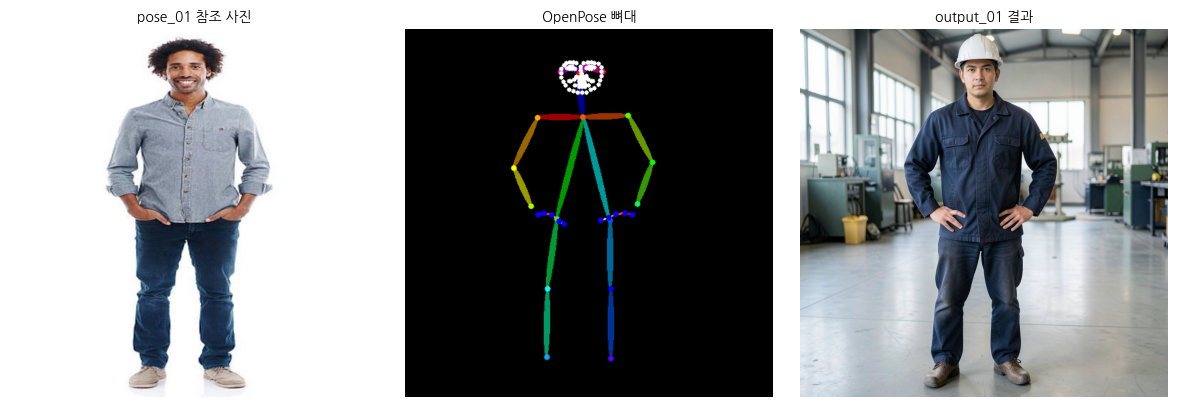

완료 14.4초 | pose_02 | 704x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton


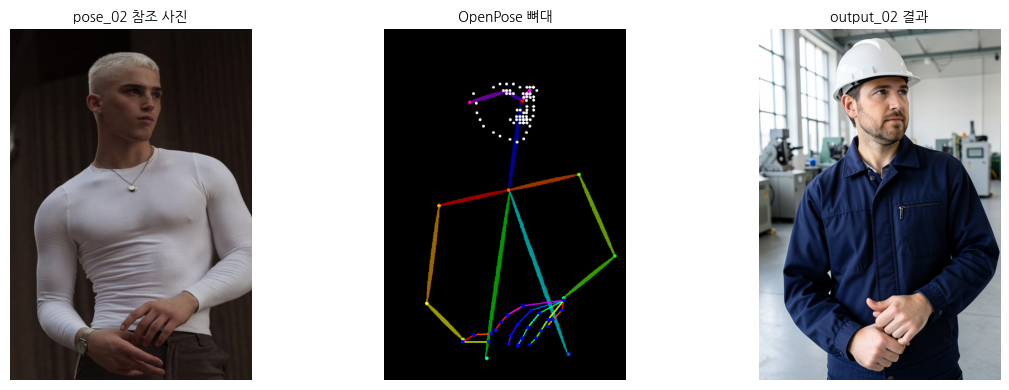

In [7]:
# [단계 7] 이 셀이 하는 일: 참조 사진마다 기본 프롬프트로 한 장씩 만들어 samples/output_XX.png 로 저장한다.
BASE_PROMPT = (
    "Subject: one factory worker in a navy work jacket and a white safety helmet. "   # 피사체
    "Action: holding exactly the pose of the reference. "                             # 동작
    "Camera: eye-level shot, 50mm lens, the whole pose in frame. "                    # 카메라
    "Lighting: soft daylight from large windows. "                                    # 조명
    "Environment: a clean, empty factory floor with machines in the background. "     # 환경
    "Style: photorealistic, natural colors."                                          # 스타일
)
SEED = 42

outputs = {}
for i, key in enumerate(refs, 1):
    outputs[key] = generate(key, BASE_PROMPT, seed=SEED)
    outputs[key].save(f"{OUT_DIR}/output_{i:02d}.png")
    show([refs[key], skeletons[key], outputs[key]], [f"{key} 참조 사진", "OpenPose 뼈대", f"output_{i:02d} 결과"])

## [단계 8] 결과에서 다시 뼈대를 뽑아 자세 비교

"같은 자세인가"를 눈대중이 아니라 **뼈대끼리** 비교합니다. 결과 이미지에 OpenPose를 한 번 더 돌려, 참조 뼈대와 결과 뼈대를 겹쳐 봅니다.

- 왼쪽: 참조 뼈대 / 가운데: 결과 뼈대 / 오른쪽: 겹친 그림(참조 = 빨강, 결과 = 초록, 겹치면 노랑)
- 노란 부분이 많을수록 자세가 맞은 것입니다. 손가락·발목처럼 작은 관절이 어긋나는지 함께 봅니다.

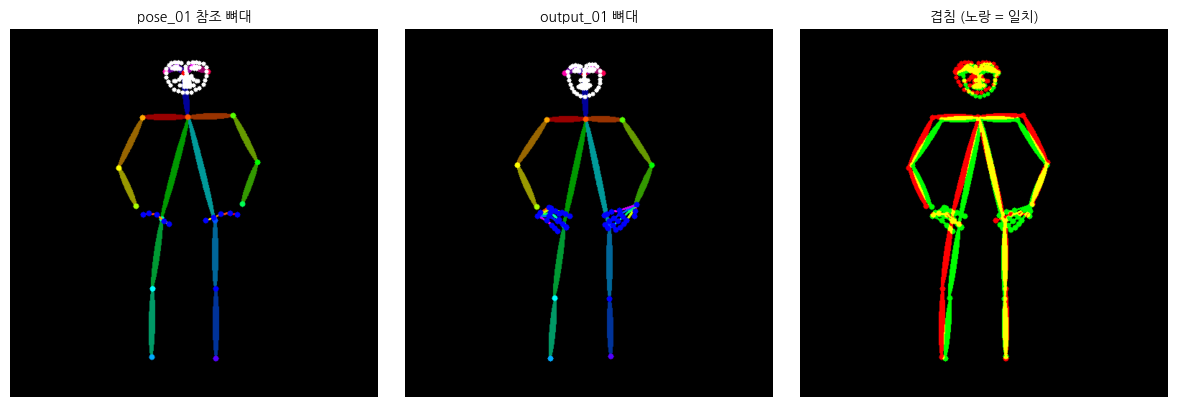

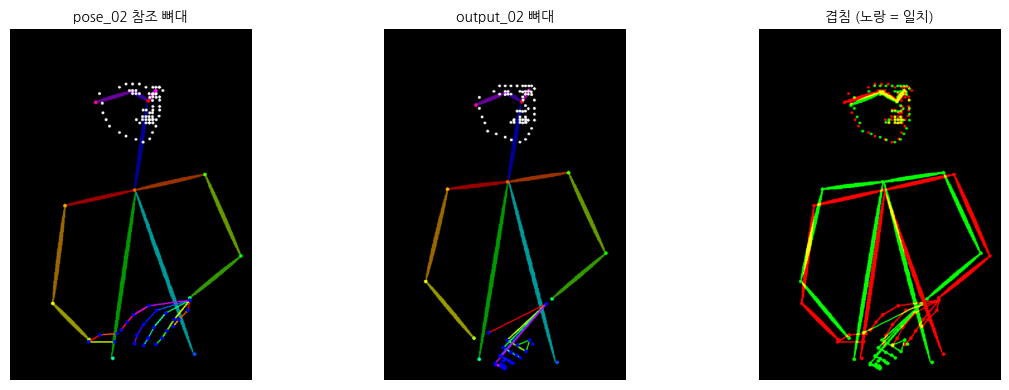

In [8]:
# [단계 8] 이 셀이 하는 일: 결과 이미지의 뼈대를 다시 뽑아 참조 뼈대와 겹쳐 보여 주고, samples/에 저장한다.
import numpy as np

def overlay(ref_pose, out_pose):
    # 참조 뼈대는 빨강, 결과 뼈대는 초록 채널에 올려 겹친 곳이 노랗게 보이게 한다
    a = np.array(ref_pose.convert("L")) > 20
    b = np.array(out_pose.convert("L").resize(ref_pose.size)) > 20
    rgb = np.zeros((*a.shape, 3), dtype=np.uint8)
    rgb[..., 0] = a * 255
    rgb[..., 1] = b * 255
    return Image.fromarray(rgb)

for i, key in enumerate(refs, 1):
    out_pose = extract_pose(outputs[key])
    ov = overlay(skeletons[key], out_pose)
    ov.save(f"{OUT_DIR}/check_{i:02d}_overlay.png")
    show([skeletons[key], out_pose, ov], [f"{key} 참조 뼈대", f"output_{i:02d} 뼈대", "겹침 (노랑 = 일치)"])

## [단계 9] 조건 실험 A·B

교안 2단계의 두 실험을 **시드 고정(42)** 으로 돌립니다. 한 번에 한 가지만 바꿔야 무엇이 결과를 바꿨는지 알 수 있습니다.

- **실험 A — 같은 포즈, 다른 프롬프트**: `pose_01` 뼈대를 고정하고 피사체·환경·스타일을 바꾼 프롬프트 3개.
- **실험 B — 같은 프롬프트, 다른 포즈**: 프롬프트를 고정하고 참조 포즈만 바꿉니다.
- **실험 C(선택) — 참조 방식 비교**: 같은 포즈·같은 프롬프트로 `ref="skeleton"` 과 `ref="photo"` 를 비교합니다.

결과는 `samples/expA_*.png`, `expB_*.png`, `expC_*.png` 로 저장됩니다. 보면서 **무엇을 바꿨고 어떻게 달라졌는지** 를 마지막 마크다운 셀에 적습니다.

완료 24.1초 | pose_01 | 1024x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton
완료 24.1초 | pose_01 | 1024x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton
완료 24.1초 | pose_01 | 1024x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton


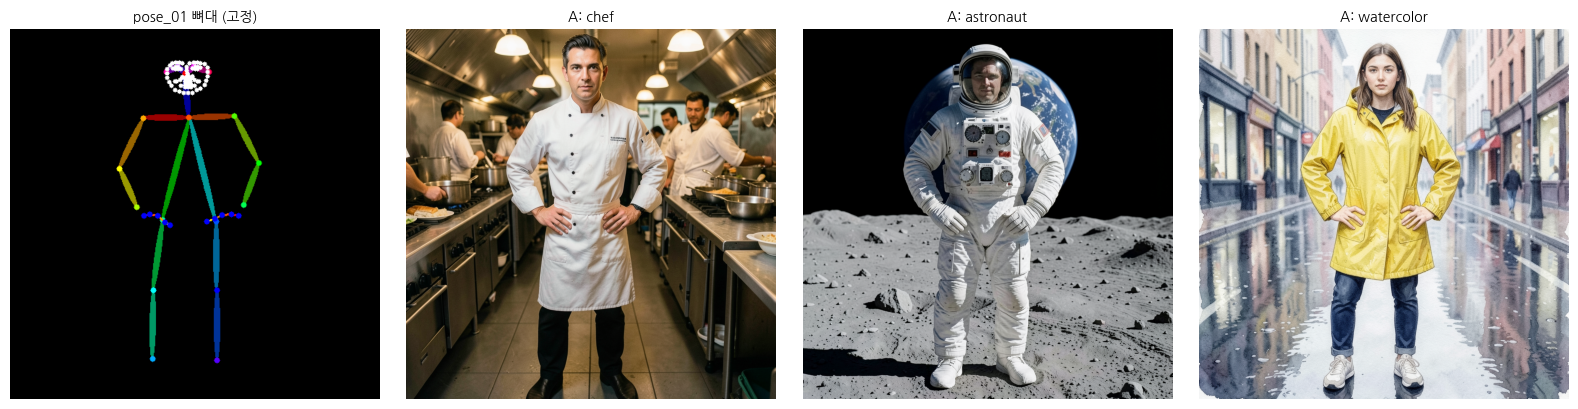

완료 24.1초 | pose_01 | 1024x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton
완료 16.1초 | pose_02 | 704x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton


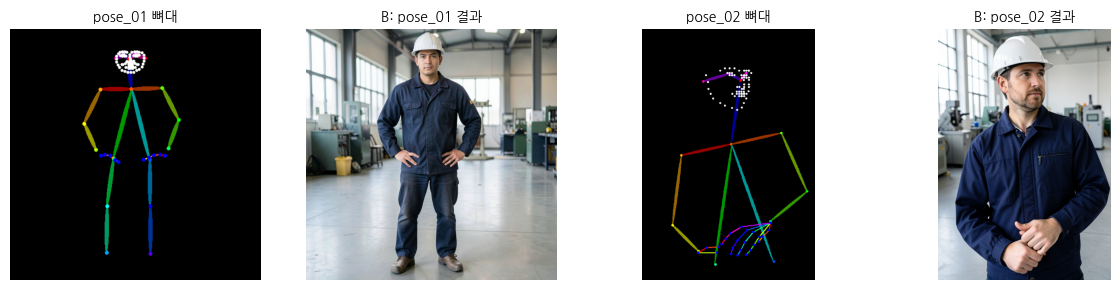

완료 26.1초 | pose_01 | 1024x1024 | seed 42 | steps 4 | cfg 1.0 | ref skeleton
완료 26.1초 | pose_01 | 1024x1024 | seed 42 | steps 4 | cfg 1.0 | ref photo


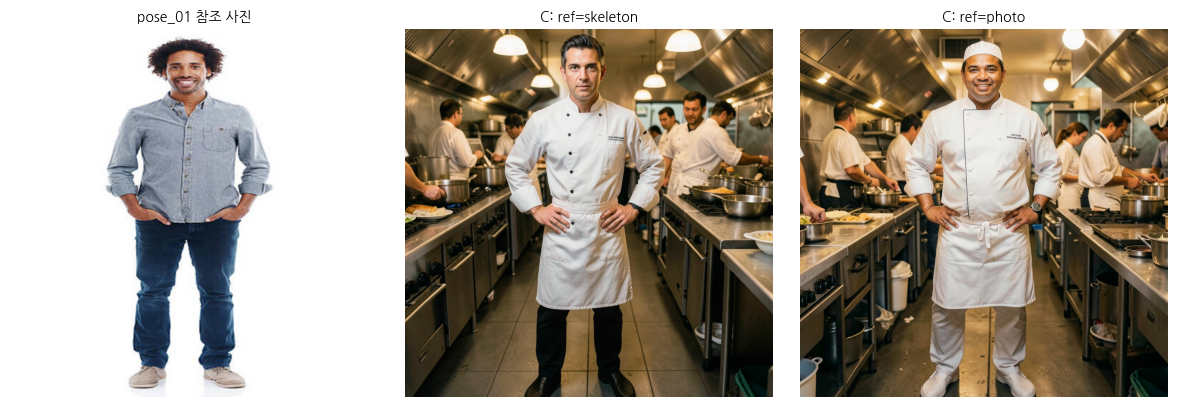

In [9]:
# [단계 9] 이 셀이 하는 일: 포즈 고정/프롬프트 변경(A), 프롬프트 고정/포즈 변경(B), 참조 방식 비교(C)를 돌려 저장한다.
EXP_A_PROMPTS = {
    "chef": ("Subject: one chef in a white uniform and apron. Action: holding exactly the pose of the reference. "
             "Camera: eye-level shot, 50mm lens, the whole pose in frame. Lighting: warm kitchen lights. "
             "Environment: a busy restaurant kitchen with steel counters. Style: photorealistic."),
    "astronaut": ("Subject: one astronaut in a white space suit with the helmet visor open. Action: holding exactly the pose of the reference. "
                  "Camera: eye-level shot, 35mm lens, the whole pose in frame. Lighting: hard sunlight with deep shadows. "
                  "Environment: a grey lunar surface with Earth in a black sky. Style: photorealistic."),
    "watercolor": ("Subject: one young woman in a yellow raincoat. Action: holding exactly the pose of the reference. "
                   "Camera: eye-level shot, the whole pose in frame. Lighting: soft overcast light. "
                   "Environment: a rainy city street with reflections. Style: loose watercolor illustration."),
}
log = []   # prompts.md 에 쓸 기록

# 실험 A: pose_01 고정, 프롬프트만 바꿈
A_KEY = list(refs)[0]
imgs, titles = [skeletons[A_KEY]], [f"{A_KEY} 뼈대 (고정)"]
for name, p in EXP_A_PROMPTS.items():
    im = generate(A_KEY, p, seed=SEED)
    im.save(f"{OUT_DIR}/expA_{name}.png")
    imgs.append(im); titles.append(f"A: {name}")
    log.append(("A", A_KEY, name, p))
show(imgs, titles)

# 실험 B: 프롬프트(BASE_PROMPT) 고정, 포즈만 바꿈
imgs, titles = [], []
for key in refs:
    im = generate(key, BASE_PROMPT, seed=SEED)
    im.save(f"{OUT_DIR}/expB_{key}.png")
    imgs += [skeletons[key], im]; titles += [f"{key} 뼈대", f"B: {key} 결과"]
    log.append(("B", key, "base", BASE_PROMPT))
show(imgs, titles, size=3)

# 실험 C(선택): 같은 포즈·프롬프트에서 참조를 뼈대 vs 원본 사진으로
imgs, titles = [refs[A_KEY]], [f"{A_KEY} 참조 사진"]
for mode in ["skeleton", "photo"]:
    im = generate(A_KEY, EXP_A_PROMPTS["chef"], seed=SEED, ref=mode)
    im.save(f"{OUT_DIR}/expC_{mode}.png")
    imgs.append(im); titles.append(f"C: ref={mode}")
    log.append(("C", A_KEY, f"chef / ref={mode}", EXP_A_PROMPTS["chef"]))
show(imgs, titles)

## [단계 10] prompts.md 작성 + 결과 내려받기

실험에 쓴 프롬프트를 `prompts.md` 로 정리하고, `samples/` 와 함께 zip으로 내려받습니다. 받은 파일을 GitHub 저장소의 같은 위치에 올리면 제출 폴더 구조가 됩니다.

```
pose-image-tool/
├── README.md
├── pose_tool.ipynb      ← 이 노트 (파일 → 다운로드 → .ipynb)
├── samples/             ← zip 안의 samples/
└── prompts.md           ← zip 안의 prompts.md
```

In [10]:
# [단계 10] 이 셀이 하는 일: 사용한 프롬프트를 prompts.md로 쓰고, samples/와 함께 zip으로 묶어 내려받는다.
from google.colab import files

lines = ["# 테스트에 쓴 프롬프트", "",
         f"- 공통 설정: FLUX.2-klein 4B (GGUF Q4_K_M), seed {SEED}, 4 steps, cfg 1.0, euler/simple, 긴 변 {MAX_SIDE}px",
         "- 포즈 지시 앞머리(뼈대 참조일 때 모든 프롬프트 앞에 붙음):", "", "```", POSE_INSTRUCTION.strip(), "```", "",
         "## 기본 프롬프트 (단계 7, 실험 B)", "", "```", BASE_PROMPT, "```", "",
         "## 실험 기록", "", "| 실험 | 포즈 | 이름 | 결과 파일 |", "|---|---|---|---|"]
for exp, key, name, _ in log:
    fname = {"A": f"expA_{name}.png", "B": f"expB_{key}.png",
             "C": f"expC_{name.split('=')[-1]}.png"}[exp]
    lines.append(f"| {exp} | {key} | {name} | samples/{fname} |")
lines += ["", "## 실험 A 프롬프트", ""]
for name, p in EXP_A_PROMPTS.items():
    lines += [f"### {name}", "", "```", p, "```", ""]

with open("/content/pose-image-tool/prompts.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

shutil.make_archive("/content/pose-image-tool", "zip", "/content/pose-image-tool")
!ls -R /content/pose-image-tool
files.download("/content/pose-image-tool.zip")

/content/pose-image-tool:
prompts.md  samples

/content/pose-image-tool/samples:
check_01_overlay.png  expB_pose_01.png	 output_02.png
check_02_overlay.png  expB_pose_02.png	 pose_01.png
expA_astronaut.png    expC_photo.png	 pose_01_skeleton.png
expA_chef.png	      expC_skeleton.png  pose_02.png
expA_watercolor.png   output_01.png	 pose_02_skeleton.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 조건 실험 관찰 기록 — 무엇을 바꿔 보았고, 어떻게 달라졌는가

### 공통 조건
- 모델 FLUX.2-klein 4B (GGUF Q4_K_M), seed 42, 4 steps, cfg 1.0, euler / simple, 긴 변 1024px, Colab T4
- 참조 = OpenPose 뼈대(몸통·손·얼굴 점)를 `ReferenceLatent`로 넣음, 프롬프트 앞에 포즈 지시 문장을 붙임
- 생성 시간: 첫 장 84.3초(모델을 GPU에 올리는 시간 포함), 이후 한 장 14~26초

### 실험 A — 같은 포즈, 다른 프롬프트 (`pose_01` 고정)
| 바꾼 것 | 자세가 유지됐나 | 달라진 점 |
|---|---|---|
| 작업자 → 요리사 (`expA_chef`) | 유지. 정면, 다리 벌림, 두 손을 허리에 짚음 | 흰 조리복·앞치마, 주방 배경. 프롬프트에 없던 다른 요리사들이 배경에 생김 |
| 작업자 → 우주인 (`expA_astronaut`) | 유지. 같은 자세 | 우주복, 달 표면, 검은 하늘의 지구까지 프롬프트대로 나옴 |
| 사진 → 수채화 (`expA_watercolor`) | 유지. 같은 자세 | 노란 우비, 비 오는 거리, 젖은 바닥 반사는 나옴. **수채화 화풍은 나오지 않고 사진처럼 나옴** |

- 프롬프트를 바꿔도 팔·다리 위치는 세 장 모두 같았다. 포즈는 뼈대가, 피사체·환경은 프롬프트가 나눠 맡는다.
- 피사체와 환경 칸은 잘 따라왔다. 스타일 칸만 안 따라왔는데, 모든 프롬프트 앞에 붙인 포즈 지시 문장에 "Generate a new **photograph**"가 들어 있어 "watercolor illustration"과 부딪힌 것으로 추정한다(확인은 안 함).
- 요리사 그림의 배경 인물처럼 **적지 않은 칸은 모델이 흔한 장면으로 채웠다**(5장 S0의 원리).

### 실험 B — 같은 프롬프트, 다른 포즈 (`BASE_PROMPT` 고정)
| 포즈 | 자세 일치 (단계 8 겹침) | 어긋난 곳 |
|---|---|---|
| pose_01 (전신, 서서 손을 주머니에) | 몸통·다리·팔꿈치 각도가 거의 겹침 | **손이 주머니 속이 아니라 허리를 짚은 모양**으로 바뀜 |
| pose_02 (상반신, 고개를 돌리고 두 손을 모음) | 고개 방향, 두 손을 몸 앞에 모은 자세가 따라옴 | 어깨선과 팔이 조금 아래로 내려와 선이 평행하게 어긋남. 헬멧이 들어가며 머리 위 여백이 생김 |

- 참고 수치: 겹침 그림에서 참조 뼈대 선 픽셀 중 결과 뼈대와 겹친 비율은 pose_01 49%, pose_02 17%. 선이 가늘어 몇 픽셀만 밀려도 안 겹친 것으로 세므로, 자세가 틀린 정도보다 낮게 나오는 수치다. 눈으로 보면 pose_02도 팔다리 방향은 같다.
- 전신·정면 자세(pose_01)가 상반신·비스듬한 자세(pose_02)보다 잘 겹쳤다.

### 실험 C — 뼈대 참조 vs 사진 참조 (`pose_01`, 요리사 프롬프트)
- 두 장 모두 같은 자세(두 손을 허리에)로 나왔다. 사진을 참조로 줘도 손이 주머니로 돌아가지 않았다.
- 사진 참조(`expC_photo`)에서는 인물 얼굴과 앞치마 끈 모양이 바뀌었고, 원본 사진의 셔츠·청바지는 따라오지 않고 프롬프트의 조리복을 따랐다.
- 그래서 손 위치가 바뀐 이유는 뼈대가 정보를 잃어서만은 아닌 것 같다. 조리복·작업복에 "주머니에 손"이 어울리지 않아 모델이 더 흔한 "허리에 손"을 고른 것으로 추정한다(확인은 안 함).

### 정리
- **결과를 더 크게 바꾼 쪽:** 프롬프트. 인물·옷·배경이 통째로 바뀌었다. 포즈를 바꾸면 자세만 바뀌고 장면은 그대로였다.
- **잘 안 따라온 것:** ① 손의 세부(주머니 → 허리), ② 수채화 화풍, ③ 상반신 사진의 어깨·팔 위치.